# 02c — Validating the bottleneck identifier

There's no ground-truth label for "your real bottleneck", so validation comes from
four directions ([proposal](../proposals/02-bottleneck-identifier.md#validation)):

1. **Pre-registration**: does the data agree with what the athlete believed beforehand?
2. **Sensitivity**: does the top limiter survive when every threshold and weight is
   perturbed?
3. **Stability over time**: does the ranking change when training changes, and stay
   put otherwise?
4. **Race case studies**: replayed as of the day before key races, did the flagged
   limiter match how the race went?

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from goalsplit_research import data, datasets, limiters as L

pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (11, 3.4), "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(2026)

ds = data.fetch_dataset()
acts = data.activities_frame(ds)
daily = data.daily_frame(ds)
races = datasets.road_races(ds, acts)
today = pd.Timestamp(ds["today"])
ctx = L.Context.at(today, acts, daily, races)
riegel = L.riegel_exponent(races)

def top(result, event):
    return L.rank(result[event], event).iloc[0]["key"]

## 1. Pre-registration

Recorded on 26 Oct 2026, before any score was computed: the athlete believed their
biggest limiter for their main road goal was **load management**.

In [2]:
current = L.assess(ctx, riegel=riegel)
for ev in L.EVENTS:
    t = L.rank(current[ev], ev)
    print(f"{ev:<15} data says: {t.iloc[0]['limiter']} ({t.iloc[0]['score']:.2f}) — "
          f"{'agrees' if t.iloc[0]['key'] == 'load' else 'differs'} with the pre-registered belief")

10K             data says: Load management and consistency (0.66) — agrees with the pre-registered belief
Half marathon   data says: Load management and consistency (0.66) — agrees with the pre-registered belief
Marathon        data says: Load management and consistency (0.74) — agrees with the pre-registered belief
Backyard ultra  data says: Load management and consistency (0.74) — agrees with the pre-registered belief


## 2. Sensitivity

1,000 re-scorings, each with every ramp endpoint moved by up to ±20% of its ramp's
width and every relevance weight scaled by ±20%. Run on all days and with race
weeks excluded. A conclusion is reported only if the top limiter holds in most
draws.

In [3]:
N = 1000
rows = []
for exclude in (False, True):
    for _ in range(N):
        params, relevance = L.perturbed(rng)
        res = L.assess(ctx, params=params, exclude_races=exclude, riegel=riegel)
        for ev in L.EVENTS:
            t = L.rank(res[ev], ev, relevance=relevance)
            rows.append({"race weeks": "excluded" if exclude else "included", "event": ev,
                         "top": t.iloc[0]["limiter"], "second": t.iloc[1]["limiter"]})
sens = pd.DataFrame(rows)
share = sens.groupby(["race weeks", "event"])["top"].value_counts(normalize=True).rename("share").reset_index()
print(share[share["share"] >= 0.01].assign(share=lambda d: (100 * d["share"]).round(1)).to_string(index=False))

race weeks          event                             top  share
  excluded            10K Load management and consistency  100.0
  excluded Backyard ultra Load management and consistency   99.9
  excluded  Half marathon Load management and consistency  100.0
  excluded       Marathon Load management and consistency   99.8
  included            10K Load management and consistency  100.0
  included Backyard ultra Load management and consistency  100.0
  included  Half marathon Load management and consistency  100.0
  included       Marathon Load management and consistency  100.0


## 3. Stability over time

The same scoring replayed at the end of each of the last 12 months, using only data
available on that date.

     as_of    event  load  base  durability  intensity  speed  top
2025-11-30 Marathon  0.86  0.72        0.21       0.60    0.0 load
2025-12-31 Marathon  0.85  0.94        0.26       0.60    0.0 base
2026-01-31 Marathon  0.83  1.00        0.26       0.60    0.0 base
2026-02-28 Marathon  0.80  1.00        0.26       0.60    0.0 base
2026-03-31 Marathon  0.81  0.97        0.20       0.60    0.0 base
2026-04-30 Marathon  0.68  0.71        0.20       0.60    0.0 base
2026-05-31 Marathon  0.71  0.67        0.21       0.45    0.0 load
2026-06-30 Marathon  0.73  0.78        0.21       0.29    0.0 base
2026-07-31 Marathon  0.69  0.90        0.21       0.60    0.0 base
2026-08-31 Marathon  0.70  0.41        0.21       0.28    0.0 load
2026-09-30 Marathon  0.76  0.27        0.21       0.03    0.0 load
2026-10-26 Marathon  0.74  0.37        0.20       0.00    0.0 load


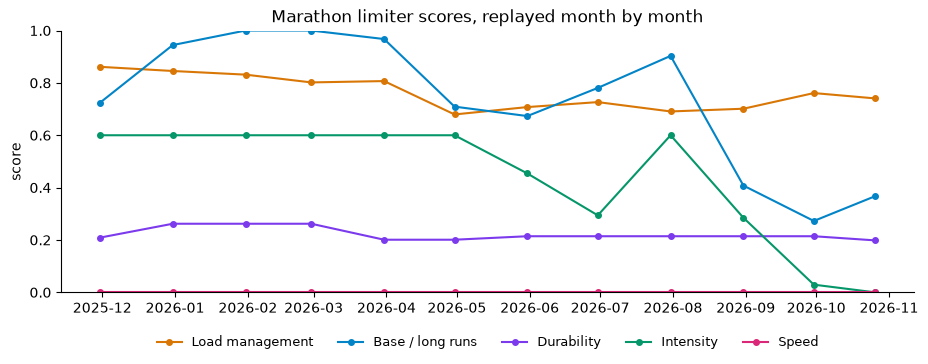

In [4]:
months = pd.date_range(today - pd.DateOffset(months=11), today, freq="ME")
timeline = []
for m in list(months) + [today]:
    c = L.Context.at(m, acts, daily, races)
    res = L.assess(c)
    for ev in ["10K", "Marathon"]:
        t = L.rank(res[ev], ev).set_index("key")
        timeline.append({"as_of": m.date(), "event": ev, **{k: t.loc[k, "score"] for k in ["load", "base", "durability", "intensity", "speed"]},
                         "top": t["score"].idxmax()})
tl = pd.DataFrame(timeline)
print(tl[tl["event"] == "Marathon"].round(2).to_string(index=False))

fig, ax = plt.subplots()
m = tl[tl["event"] == "Marathon"].set_index("as_of")
colors = {"load": "#d97706", "base": "#0284c7", "durability": "#7c3aed", "intensity": "#059669", "speed": "#db2777"}
names = {"load": "Load management", "base": "Base / long runs", "durability": "Durability", "intensity": "Intensity", "speed": "Speed"}
for k, col in colors.items():
    ax.plot(m.index, m[k], marker="o", ms=4, color=col, label=names[k])
ax.set_ylim(0, 1); ax.set_ylabel("score"); ax.set_title("Marathon limiter scores, replayed month by month")
ax.legend(frameon=False, ncols=5, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.show()

## 4. Race case studies

For key races: the ranking as of the day before (using only earlier data), set
against how the race went. VDOT is compared with the median of the athlete's road
races; late fade and drift come from the race's own streams.

In [5]:
cases = [("Pisa 10k", "2025-10-12"), ("Venice Marathon", "2025-10-26"),
         ("Firenze Half Marathon", "2026-03-29"), ("Backyard Cervia", "2026-09-26")]
median_vdot = races["vdot"].median()
event_for = {"Pisa 10k": "10K", "Venice Marathon": "Marathon", "Firenze Half Marathon": "Half marathon", "Backyard Cervia": "Backyard ultra"}
for name, date in cases:
    d = pd.Timestamp(date)
    c = L.Context.at(d - pd.Timedelta(days=1), acts, daily, races)
    t = L.rank(L.assess(c)[event_for[name]], event_for[name])
    run = acts[(acts["localDate"] == d) & acts["name"].str.startswith(name.split()[0])].head(1)
    race_row = races[races["localDate"] == d].head(1)
    print(f"{name} ({date}) — ranked for {event_for[name]}:")
    print("   " + "; ".join(f"{r.limiter} {r.score:.2f}" for r in t.itertuples() if r.score is not None and r.score > 0))
    if len(race_row):
        print(f"   race VDOT {race_row.iloc[0]['vdot']:.1f} vs median road-race VDOT {median_vdot:.1f}")
    if len(run):
        r = run.iloc[0]
        drift = "—" if pd.isna(r["decouplingPct"]) else f"{r['decouplingPct']:+.1f}%"
        fade = "—" if pd.isna(r["paceFadePct"]) else f"{r['paceFadePct']:+.1f}%"
        print(f"   in the race: drift {drift}, last-quarter pace fade {fade}")

Pisa 10k (2025-10-12) — ranked for 10K:
   Load management and consistency 0.79; Intensity distribution 0.70; Aerobic durability 0.10; Aerobic base and long runs 0.09
   race VDOT 52.6 vs median road-race VDOT 45.4
   in the race: drift +4.1%, last-quarter pace fade -3.1%
Venice Marathon (2025-10-26) — ranked for Marathon:
   Load management and consistency 0.89; Intensity distribution 0.60; Aerobic base and long runs 0.36; Aerobic durability 0.07
   race VDOT 43.6 vs median road-race VDOT 45.4
   in the race: drift +12.1%, last-quarter pace fade +15.9%


Firenze Half Marathon (2026-03-29) — ranked for Half marathon:
   Load management and consistency 0.72; Intensity distribution 0.70; Aerobic base and long runs 0.60; Aerobic durability 0.16
   race VDOT 50.4 vs median road-race VDOT 45.4
   in the race: drift -0.3%, last-quarter pace fade -10.8%
Backyard Cervia (2026-09-26) — ranked for Backyard ultra:
   Load management and consistency 0.70; Aerobic base and long runs 0.28; Aerobic durability 0.21; Intensity distribution 0.13
   in the race: drift -3.7%, last-quarter pace fade +13.2%


## Conclusions

**1. Agrees with the athlete.** For all four events the top limiter is load
management, which is what the athlete pre-registered before any analysis ran.

**2. Insensitive to the judgment calls.** Across 1,000 perturbations of every
threshold and weight, load management stays on top in 99.8–100% of draws, with or
without race weeks. No threshold or relevance weight is propping it up.

**3. Moves when training moves.** Replayed month by month, the marathon ranking
shifted for good reasons:
- **Dec 2025 – Jul 2026:** aerobic base was top. Volume was low against the athlete's
  own best and 150+ minute runs were rare.
- **Aug 2026 onwards:** the backyard-ultra block fixed base (severity 1.00 → 0.27)
  and intensity distribution (0.60 → 0.00).

Load management stayed high throughout (0.68–0.86): a persistent trait, not a
passing state.

**4. Race case studies: one clear miss.**
- **Venice Marathon:** the athlete faded hard (drift +12.1%, last-quarter pace fade
  +15.9%, VDOT 43.6 vs a median of 45.4), a classic durability failure. Yet the day
  before, durability scored only 0.07. **The durability measure uses training long
  runs, which are slow and showed little drift, so it can't see race-pace
  durability.** That's a genuine limitation of the method. Marathon-specific
  durability needs long runs with race-pace segments, or a fade-vs-pace measure,
  before it can be judged.
- **Firenze Half and Pisa 10k:** the athlete's best races (VDOT 50.4 and 52.6), run
  with no late fade (−10.8% and −3.1%, i.e. faster at the end). They were run despite
  load management being flagged, which fits it being a limiter on *consistency of
  progress* rather than on a given race day.
- **Backyard Cervia:** a 13% late fade is expected in a time-based ultra (walking
  breaks, night laps), so it says little about any limiter.

**Overall.** The identifier's top finding is robust, stable and matches the athlete's
own read. Its blind spot is race-pace durability, which training data at easy pace
can't measure.